# Grounded Answers from a Small Knowledge Pack - RAG Mini Project

**Week 24 Graded Mini Project** - IITM Pravartak, Professional Certificate Programme in Generative AI and Machine Learning

A lightweight RAG pipeline (LangChain + FAISS + Gemini) over 7 HR policy PDFs of a **fictional** company, *Kestrel Data Labs*. The notebook compares chunking strategies, an OpenAI and an open-source embedding model, and two citation-enforcing prompt templates, all with conversation memory.

| Section | Task |
|---|---|
| 0 | Setup and reproducibility |
| 1 | Data prep (tiny corpus) |
| 2 | Baseline pipeline |
| 3 | Prompt templates P1 / P2 |
| 4 | Experiments grid: retrieval benchmark (chunking × embeddings) and the run plan |
| 5 | Question set |
| 6 | Running the experiments + logging |
| 7 | Manual evaluation |
| 8 | Summary and recommendation |

The pipeline code lives in `rag.py`, the corpus generator in `make_corpus.py` and the questions in `questions.json`. API keys are read from a local `.env` file, which is not committed.

## 0. Setup and reproducibility

In [1]:
import json, os, time, platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tiktoken

import rag        # our pipeline module
import scoring    # drafts rubric scores for manual review
import summarize  # summary tables, examples and recommendation (shared with make_report.py)
from IPython.display import Markdown, display

pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
W = rag.WORK_DIR                          # "." normally, "dryrun/" when RAG_DRY_RUN=1
OUT = W / "outputs"; OUT.mkdir(parents=True, exist_ok=True)
LOG_FILE = W / "logs" / "run_log.jsonl"; LOG_FILE.parent.mkdir(parents=True, exist_ok=True)

# Set RERUN = True to call the APIs again. With False, logged results are reused; any missing run is executed
# (and LLM responses come from the on-disk cache when the prompt is identical, so results stay the same).
RERUN = False

config = {
    "llm": rag.GEMINI_MODEL, "temperature": rag.TEMPERATURE, "top_k": rag.TOP_K, "seed": rag.SEED,
    "openai_embedding": rag.OPENAI_EMBED_MODEL, "open_source_embedding": rag.OPEN_SOURCE_EMBED_MODEL,
    "vector_store": "FAISS (exact inner-product / L2 search, deterministic)",
    "python": platform.python_version(),
    **{p: version(p) for p in ["langchain", "langchain-core", "langchain-classic", "langchain-community",
                               "langchain-openai", "langchain-google-genai", "langchain-huggingface",
                               "faiss-cpu", "sentence-transformers", "pypdf"]},
}
print("DRY RUN (no API calls, stand-in LLM)" if rag.DRY_RUN else "LIVE RUN",
      "| keys present ->", {k: bool(os.getenv(k)) for k in ["GOOGLE_API_KEY", "OPENAI_API_KEY"]})
pd.Series(config, name="value").to_frame()

LIVE RUN | keys present -> {'GOOGLE_API_KEY': True, 'OPENAI_API_KEY': True}


,value
llm,gemini-3.5-flash-lite
temperature,0.0
top_k,4
seed,42
openai_embedding,text-embedding-3-small
open_source_embedding,BAAI/bge-small-en-v1.5
vector_store,"FAISS (exact inner-product / L2 search, deterministic)"
python,3.12.14
langchain,1.4.6
langchain-core,1.6.12


# Task 1: Data prep (tiny corpus)

**Topic:** HR policies of one company. Seven short PDFs, generated by `make_corpus.py`, each with a clear title and source path. The company is fictional, which guarantees the LLM cannot answer from what it learned in training. Any correct answer has to come from retrieval, which makes groundedness and refusal behaviour easy to test.

In [2]:
import make_corpus
make_corpus.build()                    # (re)creates corpus/*.pdf deterministically

pages = rag.load_corpus()              # pypdf text extraction -> one Document per page
inventory = (pd.DataFrame([{**p.metadata, "words": len(p.page_content.split())} for p in pages])
               .groupby(["doc_title", "source"]).agg(pages=("page", "max"), words=("words", "sum")).reset_index())
inventory.to_csv(OUT / "corpus_inventory.csv", index=False)
print(f"{len(inventory)} documents, {len(pages)} pages, {inventory['words'].sum()} words")
inventory

wrote corpus/01_leave_policy.pdf (3 pages)
wrote corpus/02_remote_work_policy.pdf (2 pages)
wrote corpus/03_travel_expense_policy.pdf (2 pages)
wrote corpus/04_it_security_policy.pdf (2 pages)
wrote corpus/05_code_of_conduct.pdf (2 pages)
wrote corpus/06_performance_promotion_policy.pdf (2 pages)
wrote corpus/07_learning_development_policy.pdf (2 pages)
7 documents, 15 pages, 1820 words


,doc_title,source,pages,words
0,Code of Conduct,corpus/05_code_of_conduct.pdf,2,243
1,IT and Information Security Policy,corpus/04_it_security_policy.pdf,2,247
2,Learning and Development Policy,corpus/07_learning_development_policy.pdf,2,180
3,Leave Policy,corpus/01_leave_policy.pdf,3,420
4,Performance and Promotion Policy,corpus/06_performance_promotion_policy.pdf,2,217
5,Remote and Hybrid Work Policy,corpus/02_remote_work_policy.pdf,2,259
6,Travel and Expense Policy,corpus/03_travel_expense_policy.pdf,2,254


In [3]:
# Metadata kept on every page / chunk: doc_title, source path, page number (+ chunk_id after splitting)
print(pages[1].metadata)
print(pages[1].page_content[:400])

{'doc_title': 'Leave Policy', 'source': 'corpus/01_leave_policy.pdf', 'page': 2}
4. Carry forward and encashment
Employees may carry forward a maximum of 10 unused annual leave days into the next leave year.
Any unused balance above 10 days lapses on 31 December and is not paid out, except on
resignation, when up to 15 accrued days are encashed at the basic salary rate.
5. Applying for leave
Planned annual leave must be applied for in PeopleDesk at least 7 calendar days in adv


# Task 2: Baseline pipeline

`PyPDF loader -> RecursiveCharacterTextSplitter (600 chars, 15% overlap) -> embeddings -> FAISS -> retriever (k=4) -> Gemini -> citation prompt -> answer + citations[]`, with `ConversationBufferMemory`.

Design choices:
- **Splitting is done page by page**, so a chunk never crosses a page boundary and its `[title#page]` label is always exact. Each chunk gets a `chunk_id` such as `01_leave_policy-p2-c0`.
- **Each context passage is labelled** with the exact citation string the model must copy, for example `[Leave Policy#2]`.
- **The chain is an LCEL Runnable graph:** `condense follow-up -> retrieve -> prompt -> LLM`.
  - A short "condense" step uses the conversation memory to rewrite follow-ups such as *"how many of **those** can I carry forward?"* into a standalone search query. Without this step, retrieval for follow-ups would fail.
  - The full history is also passed to the answer prompt.
- **`ConversationBufferMemory`** (from `langchain_classic`, its home since LangChain 1.0) stores every turn and is cleared between conversations.
- **Output** per question: `answer`, `citations=[...]`, `used_chunks`, token counts and latency.

In [4]:
chunks = rag.split_docs(pages, chunk_size=600, overlap_pct=0.15)
print(len(chunks), "chunks; example metadata:", chunks[5].metadata)
print(chunks[5].page_content)

29 chunks; example metadata: {'doc_title': 'Leave Policy', 'source': 'corpus/01_leave_policy.pdf', 'page': 3, 'chunk_id': '01_leave_policy-p3-c1'}
day off, to be used within 60 days.
9. Leave without pay
Leave without pay of up to 30 days may be granted once annual leave is exhausted, with
department head and HR approval.


In [5]:
import inspect
print(inspect.getsource(rag.build_chain))
print(inspect.getsource(rag.RAGSession))

def build_chain(vectorstore, prompt_id):
    llm = get_llm()
    retriever = vectorstore.as_retriever(search_kwargs={"k": TOP_K})

    def condense(x):
        if not x["chat_history"]:
            return {"text": x["question"], "usage": {}}
        msg = (CONDENSE | llm).invoke(x)
        return {"text": msg.text.strip(), "usage": msg.usage_metadata or {}}

    def generate(x):
        msg = (PROMPTS[prompt_id] | llm).invoke({"context": format_context(x["docs"]),
                                                 "chat_history": x["chat_history"], "question": x["question"]})
        return msg

    return (
        RunnablePassthrough.assign(condensed=RunnableLambda(condense))
        | RunnablePassthrough.assign(docs=lambda x: retriever.invoke(x["condensed"]["text"]))
        | RunnablePassthrough.assign(llm_msg=RunnableLambda(generate))
    )

class RAGSession:
    """One conversation: the chain + a ConversationBufferMemory that is reset between triples."""

    def __init__(self, vec

# Task 3: Prompt templates

Both prompts share the same grounding rules: use only the context, cite `[Title#page]` after every factual sentence, and give a fixed "don't know" sentence when the answer is missing.
- **P1 (concise)** adds the ≤120-token limit.
- **P2 (reasoned)** forces a visible structure: at most 2 `Evidence:` bullets, each with a citation, then a short `Answer:` of at most 60 words. The model has to point to its support before answering, without revealing any private chain-of-thought.

In [6]:
for pid, p in rag.PROMPTS.items():
    print(f"===== {pid} =====")
    print(p.messages[0].prompt.template.replace("{context}", "<retrieved passages>"))
    print()

===== P1 =====
You are an HR policy assistant for Kestrel Data Labs. Use ONLY the context passages below; do not use outside knowledge. Every factual sentence must end with a citation in the exact form [Document Title#page], copied from the passage labels. If the context does not contain the answer, reply exactly: "I don't know based on the provided policies." and add no citations. Answer in at most 120 tokens (2-4 short sentences).

Context:
<retrieved passages>

===== P2 =====
You are an HR policy assistant for Kestrel Data Labs. Use ONLY the context passages below; do not use outside knowledge. Every factual sentence must end with a citation in the exact form [Document Title#page], copied from the passage labels. If the context does not contain the answer, reply exactly: "I don't know based on the provided policies." and add no citations. Format your reply exactly as:
Evidence:
- <short quote or paraphrase from a passage> [Title#page]
- <second supporting snippet> [Title#page]
Answe

# Task 4: Experiments grid

## 4a. Retrieval benchmark: all chunking configurations × both embeddings (no LLM needed)

Before spending any LLM calls, retrieval quality is measured directly against the gold answer key in `questions.json`, where every answerable question has its gold page(s). For the 8 answerable questions:
- **Recall@4:** share of gold pages found in the top 4 chunks.
- **Precision@4:** share of the top-4 chunks that come from a gold page.
- **MRR:** 1 / rank of the first relevant chunk.
- **Cost and latency:** embedding tokens, OpenAI cost, index build time and query time.

Follow-up questions are evaluated with their standalone `retrieval_query`, because retrieval is what is measured here, not the rewrite step.

In [7]:
QUESTIONS = json.load(open("questions.json"))
answerable = [q for q in QUESTIONS if q["gold_pages"]]
enc = tiktoken.get_encoding("cl100k_base")

# the 6 grid cells from the brief + the 15% overlap used by the baseline and the chunk-size runs
CHUNK_CONFIGS = [(300, .10), (300, .15), (300, .20), (600, .10), (600, .15), (600, .20), (1000, .10), (1000, .15), (1000, .20)]
bench_rows, stores = [], {}
for emb in ["openai", "bge"]:
    for cs, ov in CHUNK_CONFIGS:
        ch = rag.split_docs(pages, cs, ov)
        t0 = time.perf_counter(); vs = rag.build_vectorstore(ch, emb); build_s = time.perf_counter() - t0
        stores[(emb, cs, ov)] = vs
        rec, prec, rr, q_lat = [], [], [], []
        for q in answerable:
            t1 = time.perf_counter(); hits = vs.similarity_search(q["retrieval_query"], k=rag.TOP_K); q_lat.append(time.perf_counter() - t1)
            hp = [f"{d.metadata['doc_title']}#{d.metadata['page']}" for d in hits]
            gold = set(q["gold_pages"])
            rec.append(len(gold & set(hp)) / len(gold))
            prec.append(sum(h in gold for h in hp) / len(hp))
            rr.append(next((1 / (i + 1) for i, h in enumerate(hp) if h in gold), 0))
        tokens = sum(len(enc.encode(c.page_content)) for c in ch)
        bench_rows.append({"embedding": emb, "chunk_size": cs, "overlap": f"{int(ov*100)}%", "chunks": len(ch),
                           "recall@4": np.mean(rec), "precision@4": np.mean(prec), "MRR": np.mean(rr),
                           "embed_tokens": tokens,
                           "openai_cost_usd": tokens / 1e6 * rag.OPENAI_EMBED_PRICE_PER_1M if emb == "openai" else 0.0,
                           "index_build_s": build_s, "query_ms": np.mean(q_lat) * 1000})
bench = pd.DataFrame(bench_rows)
bench.round(4).to_csv(OUT / "retrieval_benchmark.csv", index=False)
bench.round({"recall@4": 3, "precision@4": 3, "MRR": 3, "openai_cost_usd": 6, "index_build_s": 2, "query_ms": 1})

/Users/arpit/Documents/claude/IITM-PravartakGenAI-ML-Program/Week-24-Graded-Mini-Project/.venv/lib/python3.12/site-packages/langchain_classic/embeddings/cache.py:58: UserWarning: Using default key encoder: SHA-1 is *not* collision-resistant. While acceptable for most cache scenarios, a motivated attacker can craft two different payloads that map to the same cache key. If that risk matters in your environment, supply a stronger encoder (e.g. SHA-256 or BLAKE2) via the `key_encoder` argument. If you change the key encoder, consider also creating a new cache, to avoid (the potential for) collisions with existing keys.
  _warn_about_sha1_encoder()


/Users/arpit/Documents/claude/IITM-PravartakGenAI-ML-Program/Week-24-Graded-Mini-Project/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1027 16:23:40.841000 86752 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


Loading weights:   0%|                                                                                                                                                                                                                                                                              | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 7934.02it/s]

,embedding,chunk_size,overlap,chunks,recall@4,precision@4,MRR,embed_tokens,openai_cost_usd,index_build_s,query_ms
0,openai,300,10%,50,1.0,0.594,1.000,2491,0.000050,0.54,4.4
1,openai,300,15%,50,1.0,0.594,1.000,2511,0.000050,0.02,0.4
2,openai,300,20%,51,1.0,0.594,1.000,2532,0.000051,0.02,0.3
3,openai,600,10%,29,1.0,0.312,1.000,2520,0.000050,0.01,0.4
4,openai,600,15%,29,1.0,0.344,1.000,2581,0.000052,0.01,0.4
5,openai,600,20%,29,1.0,0.344,1.000,2700,0.000054,0.01,0.3
6,openai,1000,10%,15,1.0,0.250,0.917,2456,0.000049,0.01,0.3
7,openai,1000,15%,15,1.0,0.250,0.917,2456,0.000049,0.00,0.3
8,openai,1000,20%,15,1.0,0.250,0.917,2456,0.000049,0.00,0.3
9,bge,300,10%,50,1.0,0.500,1.000,2491,0.000000,9.89,0.8


*Index build times include embedding the chunks. Embeddings are cached on disk, so after the first run the build time mostly reflects cache reads. The first-run timings for the live API vs local CPU are measured separately in 4b.*

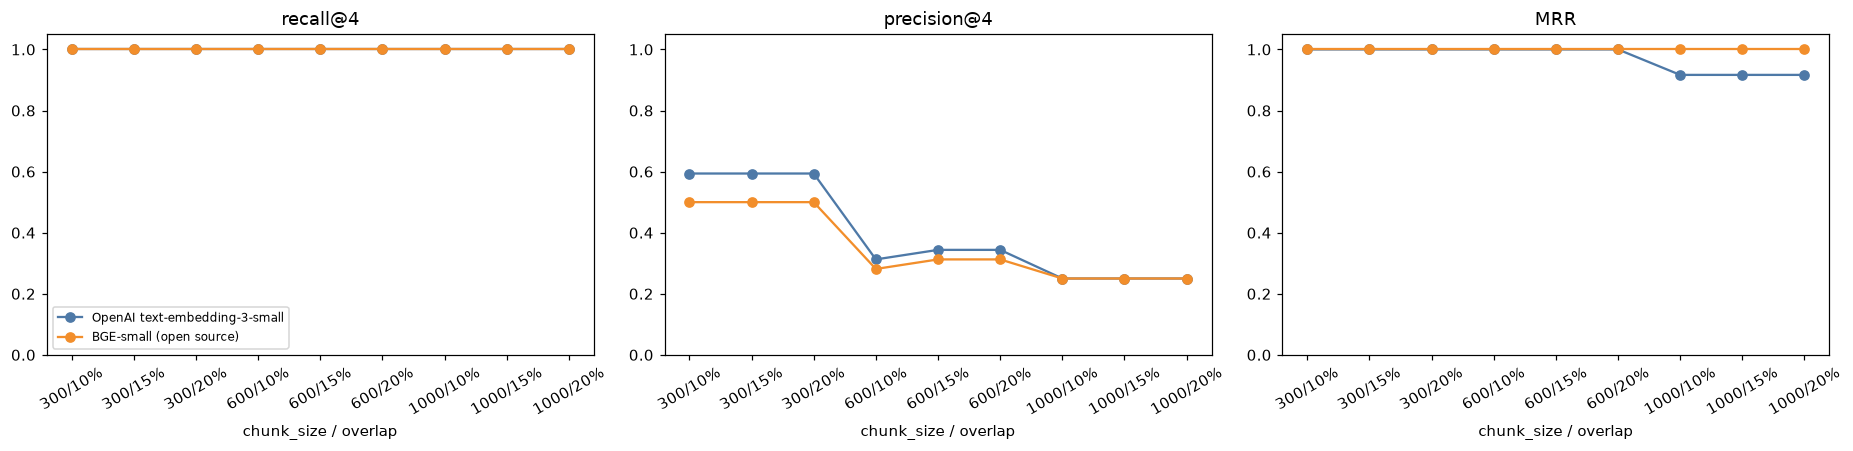

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
lab = bench["chunk_size"].astype(str) + "/" + bench["overlap"]
for ax, m in zip(axes, ["recall@4", "precision@4", "MRR"]):
    for emb, c in [("openai", "#4e79a7"), ("bge", "#f28e2b")]:
        s = bench[bench["embedding"] == emb]
        ax.plot(lab[s.index], s[m], marker="o", label={"openai": "OpenAI text-embedding-3-small", "bge": "BGE-small (open source)"}[emb], color=c)
    ax.set_title(m); ax.set_xlabel("chunk_size / overlap"); ax.tick_params(axis="x", rotation=30); ax.set_ylim(0, 1.05)
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig(OUT / "01_retrieval_benchmark.png"); plt.show()

## 4b. Embedding cost and latency (cold, uncached)

In [9]:
# Fresh, uncached embedding of the baseline chunks + all queries, to compare real API vs local CPU latency
from langchain_openai import OpenAIEmbeddings
from langchain_huggingface import HuggingFaceEmbeddings
base_chunks = [c.page_content for c in rag.split_docs(pages, 600, .15)]
queries = [q["retrieval_query"] for q in QUESTIONS]
cold = []
openai_mk = (lambda: HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")) if rag.DRY_RUN             else (lambda: OpenAIEmbeddings(model=rag.OPENAI_EMBED_MODEL))
for name, mk in [("OpenAI text-embedding-3-small", openai_mk),
                 ("BGE-small-en-v1.5 (local CPU)", lambda: HuggingFaceEmbeddings(model_name=rag.OPEN_SOURCE_EMBED_MODEL,
                                                                                  encode_kwargs={"normalize_embeddings": True}))]:
    m = mk()
    t0 = time.perf_counter(); v = m.embed_documents(base_chunks); t_docs = time.perf_counter() - t0
    t0 = time.perf_counter(); [m.embed_query(q) for q in queries]; t_q = (time.perf_counter() - t0) / len(queries)
    toks = sum(len(enc.encode(t)) for t in base_chunks + queries)
    cold.append({"model": name, "dimensions": len(v[0]), f"embed {len(base_chunks)} chunks (s)": round(t_docs, 2),
                 "per query (ms)": round(t_q * 1000, 1), "tokens": toks,
                 "cost this corpus (USD)": round(toks / 1e6 * rag.OPENAI_EMBED_PRICE_PER_1M, 6) if "OpenAI" in name else 0.0,
                 "cost per 1M tokens (USD)": rag.OPENAI_EMBED_PRICE_PER_1M if "OpenAI" in name else "0 (self-hosted)",
                 "runs where": "OpenAI cloud API" if "OpenAI" in name else "this laptop, no network"})
cold = pd.DataFrame(cold).set_index("model")
cold.to_csv(OUT / "embedding_cost_latency.csv")
cold.T

Loading weights:   0%|                                                                                                                                                                                                                                                                              | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 199/199 [00:00<00:00, 14158.41it/s]

model,OpenAI text-embedding-3-small,BGE-small-en-v1.5 (local CPU)
dimensions,1536,384
embed 29 chunks (s),3.19,0.62
per query (ms),349.1,16.2
tokens,2709,2709
cost this corpus (USD),0.000054,0.0
cost per 1M tokens (USD),0.02,0 (self-hosted)
runs where,OpenAI cloud API,"this laptop, no network"


## 4c. LLM run plan (one factor at a time)

From the baseline (600 / 15% / OpenAI / P1), each run changes **exactly one** factor:

| Run | Change vs baseline | Tests |
|---|---|---|
| R1 | baseline | - |
| R2 | chunk 300 | smaller chunks |
| R3 | chunk 1000 | larger chunks |
| R4 | overlap 10% | less overlap |
| R5 | overlap 20% | more overlap |
| R6 | open-source BGE embeddings | embedding model |
| R7 | prompt P2 | prompt template |

In [10]:
RUNS = [
    {"run_id": "R1", "chunk_size": 600,  "overlap": .15, "embedding": "openai", "prompt_id": "P1", "change": "baseline"},
    {"run_id": "R2", "chunk_size": 300,  "overlap": .15, "embedding": "openai", "prompt_id": "P1", "change": "chunk 300"},
    {"run_id": "R3", "chunk_size": 1000, "overlap": .15, "embedding": "openai", "prompt_id": "P1", "change": "chunk 1000"},
    {"run_id": "R4", "chunk_size": 600,  "overlap": .10, "embedding": "openai", "prompt_id": "P1", "change": "overlap 10%"},
    {"run_id": "R5", "chunk_size": 600,  "overlap": .20, "embedding": "openai", "prompt_id": "P1", "change": "overlap 20%"},
    {"run_id": "R6", "chunk_size": 600,  "overlap": .15, "embedding": "bge",    "prompt_id": "P1", "change": "open-source embeddings"},
    {"run_id": "R7", "chunk_size": 600,  "overlap": .15, "embedding": "openai", "prompt_id": "P2", "change": "prompt P2"},
]
pd.DataFrame(RUNS).set_index("run_id")

,chunk_size,overlap,embedding,prompt_id,change
run_id,,,,,
R1,600,0.15,openai,P1,baseline
R2,300,0.15,openai,P1,chunk 300
R3,1000,0.15,openai,P1,chunk 1000
R4,600,0.10,openai,P1,overlap 10%
R5,600,0.20,openai,P1,overlap 20%
R6,600,0.15,bge,P1,open-source embeddings
R7,600,0.15,openai,P2,prompt P2


# Task 5: Question set

There are 10 questions in 4 conversations: **6 factual**, **2 follow-up / multi-hop** and **2 boundary** questions (the answer is not in the pack, so the system should say it doesn't know).
- Conversations A, B and C are 3-turn triples (Q1→Q2→Q3). Memory is reset after each triple.
- Q2 depends on Q1 ("those" = annual leave days).
- Q8 is multi-hop. It follows a promotion question and needs the *travel* policy plus the L5 level from the conversation.
- Q6 and Q9 are boundary questions placed *inside* conversations, to test that the history doesn't tempt the model to over-reach.

In [11]:
pd.DataFrame(QUESTIONS)[["qid", "conv", "turn", "type", "question", "gold_pages", "gold_answer"]]

,qid,conv,turn,type,question,gold_pages,gold_answer
0,Q1,A,1,factual,How many days of annual leave do full-time employees get each year?,[Leave Policy#1],"24 days per leave year, accruing at 2 days per completed month."
1,Q2,A,2,follow-up,"How many of those can I carry forward, and what happens to the rest?",[Leave Policy#2],Up to 10 days carry forward; anything above 10 lapses on 31 December and is not paid out (except up to 15 days encas...
2,Q3,A,3,factual,What notice is needed to apply for planned leave?,[Leave Policy#2],At least 7 calendar days in PeopleDesk; more than 5 consecutive working days needs 21 days' notice and manager + dep...
3,Q4,B,1,factual,Which flight class can I book for a 4-hour domestic flight?,[Travel and Expense Policy#1],Economy class (standard for flights up to 6 hours).
4,Q5,B,2,factual,What is the daily allowance for international travel?,[Travel and Expense Policy#2],USD 75 per day (not paid on days meals are provided).
5,Q6,B,3,boundary,Does the company reimburse my gym membership?,[],Not covered by the policies -> should say it doesn't know.
6,Q7,C,1,factual,What are the eligibility criteria for promotion?,[Performance and Promotion Policy#2],At least 18 months in current level and a rating of 4 or higher in each of the last two review cycles.
7,Q8,C,2,follow-up,"Once I'm promoted to L5, which class can I fly on an 8-hour flight?",[Travel and Expense Policy#1],"Business class (flights over 6 hours, level L5 and above)."
8,Q9,C,3,boundary,What is the CEO's annual salary?,[],Not in the policies -> should say it doesn't know.
9,Q10,D,1,factual,"I clicked a link in a phishing email. How quickly must I report it, and to whom?",[IT and Information Security Policy#2],"Within 1 hour, to Security Operations at security@kestrel.example or hotline extension 4444."


# Task 6: Running the experiments and logging

Every answer is appended to `logs/run_log.jsonl` with:
- **identifiers:** run_id, question
- **the configuration:** chunk_size, overlap, embedding, prompt_id, llm, top_k, temperature
- **the outputs:** answer, citations, used_chunks (IDs) and their pages, the standalone (condensed) question, tokens and latency

A flat CSV copy is also written to `logs/run_log.csv`.

In [12]:
done = set()
if LOG_FILE.exists() and not RERUN:
    done = {(r["run_id"], r["qid"]) for r in map(json.loads, LOG_FILE.read_text().splitlines())}
elif RERUN and LOG_FILE.exists():
    LOG_FILE.unlink()

for run in RUNS:
    if all((run["run_id"], q["qid"]) in done for q in QUESTIONS):
        continue
    ch = rag.split_docs(pages, run["chunk_size"], run["overlap"])
    vs = rag.build_vectorstore(ch, run["embedding"])
    session = rag.RAGSession(vs, run["prompt_id"])
    current_conv = None
    for q in QUESTIONS:
        if q["conv"] != current_conv:          # new triple -> reset memory
            session.reset(); current_conv = q["conv"]
        res = session.ask(q["question"])
        row = {**{k: run[k] for k in ["run_id", "chunk_size", "embedding", "prompt_id", "change"]},
               "overlap": f"{int(run['overlap']*100)}%", "llm": rag.GEMINI_MODEL, "top_k": rag.TOP_K,
               "temperature": rag.TEMPERATURE, "qid": q["qid"], "conv": q["conv"], "turn": q["turn"],
               "q_type": q["type"], "question": q["question"], **res, "timestamp": time.strftime("%Y-%m-%d %H:%M:%S")}
        with LOG_FILE.open("a") as f:
            f.write(json.dumps(row) + "\n")
        print(run["run_id"], q["qid"], f"{res['latency_s']}s", res["citations"])

log = pd.DataFrame(map(json.loads, LOG_FILE.read_text().splitlines()))
log = log.drop_duplicates(["run_id", "qid"], keep="last").sort_values(["run_id", "qid"], key=lambda s: s.str.extract(r"(\d+)")[0].astype(int) if s.name == "qid" else s)
log.to_csv(W / "logs" / "run_log.csv", index=False)
print(len(log), "logged answers")
log[["run_id", "qid", "question", "answer", "citations", "used_chunks", "input_tokens", "output_tokens", "latency_s"]].head(10)

70 logged answers


,run_id,qid,question,answer,citations,used_chunks,input_tokens,output_tokens,latency_s
0,R1,Q1,How many days of annual leave do full-time employees get each year?,Full-time employees receive 24 days of annual leave per leave year [Leave Policy#1].,[Leave Policy#1],"[01_leave_policy-p1-c1, 01_leave_policy-p2-c1, 01_leave_policy-p2-c0, 01_leave_policy-p3-c0]",632,21,7.89
1,R1,Q2,"How many of those can I carry forward, and what happens to the rest?",Employees may carry forward a maximum of 10 unused annual leave days [Leave Policy#2]. Any unused balance above 10 d...,[Leave Policy#2],"[01_leave_policy-p2-c0, 01_leave_policy-p1-c1, 01_leave_policy-p2-c1, 01_leave_policy-p3-c0]",778,86,13.70
2,R1,Q3,What notice is needed to apply for planned leave?,Planned annual leave must be applied for in PeopleDesk at least 7 calendar days in advance [Leave Policy#2]. Leave o...,[Leave Policy#2],"[01_leave_policy-p2-c0, 01_leave_policy-p3-c1, 01_leave_policy-p3-c0, 01_leave_policy-p1-c1]",920,69,13.14
3,R1,Q4,Which flight class can I book for a 4-hour domestic flight?,Economy class is the standard for all flights with a scheduled duration of up to 6 hours [Travel and Expense Policy#...,[Travel and Expense Policy#1],"[03_travel_expense_policy-p1-c1, 03_travel_expense_policy-p1-c0, 03_travel_expense_policy-p2-c0, 02_remote_work_poli...",636,53,6.81
4,R1,Q5,What is the daily allowance for international travel?,The daily allowance for meals and local incidentals for international travel is USD 75 per day [Travel and Expense P...,[Travel and Expense Policy#2],"[03_travel_expense_policy-p2-c0, 03_travel_expense_policy-p1-c0, 03_travel_expense_policy-p1-c1, 02_remote_work_poli...",904,61,13.58
5,R1,Q6,Does the company reimburse my gym membership?,I don't know based on the provided policies.,[],"[07_learning_development_policy-p2-c0, 03_travel_expense_policy-p2-c1, 02_remote_work_policy-p2-c0, 03_travel_expens...",987,19,13.89
6,R1,Q7,What are the eligibility criteria for promotion?,"To be eligible for promotion, an employee must have spent at least 18 months in their current level [Performance and...",[Performance and Promotion Policy#2],"[06_performance_promotion_policy-p2-c0, 06_performance_promotion_policy-p1-c0, 07_learning_development_policy-p2-c1,...",574,58,6.57
7,R1,Q8,"Once I'm promoted to L5, which class can I fly on an 8-hour flight?",Employees at level L5 and above may book business class for flights longer than 6 hours [Travel and Expense Policy#1].,[Travel and Expense Policy#1],"[03_travel_expense_policy-p1-c1, 03_travel_expense_policy-p1-c0, 06_performance_promotion_policy-p2-c0, 01_leave_pol...",917,45,14.06
8,R1,Q9,What is the CEO's annual salary?,I don't know based on the provided policies.,[],"[06_performance_promotion_policy-p2-c1, 07_learning_development_policy-p2-c0, 07_learning_development_policy-p1-c0, ...",895,20,12.96
9,R1,Q10,"I clicked a link in a phishing email. How quickly must I report it, and to whom?","Any suspected security incident, including a clicked phishing email, must be reported within 1 hour of discovery [IT...",[IT and Information Security Policy#2],"[04_it_security_policy-p2-c0, 05_code_of_conduct-p2-c0, 05_code_of_conduct-p1-c1, 02_remote_work_policy-p2-c1]",569,66,7.17


In [13]:
# Example: one complete log record
print(json.dumps(log.iloc[1].to_dict(), indent=2, default=str))

{
  "run_id": "R1",
  "chunk_size": 600,
  "embedding": "openai",
  "prompt_id": "P1",
  "change": "baseline",
  "overlap": "15%",
  "llm": "gemini-3.5-flash-lite",
  "top_k": 4,
  "temperature": 0.0,
  "qid": "Q2",
  "conv": "A",
  "turn": 2,
  "q_type": "follow-up",
  "question": "How many of those can I carry forward, and what happens to the rest?",
  "answer": "Employees may carry forward a maximum of 10 unused annual leave days [Leave Policy#2]. Any unused balance above 10 days lapses on 31 December and is not paid out, except upon resignation when up to 15 accrued days are encashed [Leave Policy#2].",
  "citations": [
    "Leave Policy#2"
  ],
  "standalone_question": "How many days of annual leave can full-time employees carry forward to the next year, and what happens to the remaining days?",
  "used_chunks": [
    "01_leave_policy-p2-c0",
    "01_leave_policy-p1-c1",
    "01_leave_policy-p2-c1",
    "01_leave_policy-p3-c0"
  ],
  "used_pages": [
    "Leave Policy#1",
    "Leav

# Task 7: Manual evaluation

Each of the 70 answers (7 runs × 10 questions) is scored against the gold answer key and the chunks that were actually retrieved. `scoring.py` first drafts every score by applying the rubric mechanically (key facts present? citations pointing to retrieved and gold pages? length? refusal?). Each answer is then **read and the scores corrected by hand** in `logs/manual_scores.csv` (column `reviewed`).

| Criterion | Scale | Meaning |
|---|---|---|
| Relevance | 0-2 | 2 = fully answers the question; 1 = partly; 0 = wrong / off-topic |
| Groundedness | 0-2 | 2 = every claim supported by the retrieved chunks; 0 = contains unsupported claims |
| Citation correctness | 0-2 | 2 = all citations point to the page that supports the claim; 1 = some missing/extra; 0 = none or wrong |
| Conciseness | 0-1 | 1 = within the length limit and no padding |
| Memory continuity | 0-2 | turns 2-3 only: 2 = correctly uses / is not confused by prior turns |
| Refusal correct? | 0-1 | boundary questions only: 1 = says it doesn't know and makes nothing up |

Two automatic checks support the manual scoring:
- **Citation check:** every cited `[title#page]` must exist among the retrieved chunks, and at least one must be a gold page.
- **Length check:** the answer's token count against the 120-token limit.

In [14]:
REFUSAL = "don't know"
qmeta = pd.DataFrame(QUESTIONS).set_index("qid")
def auto_checks(r):
    gold = set(qmeta.loc[r["qid"], "gold_pages"])
    cited, used = set(r["citations"]), set(r["used_pages"])
    refused = REFUSAL in r["answer"].lower()
    return pd.Series({
        "auto_refused": refused,
        "auto_cites_in_retrieved": cited <= used if cited else None,
        "auto_cites_gold": bool(cited & gold) if gold else None,
        "auto_gold_retrieved": bool(used & gold) if gold else None,
        "auto_within_120_tokens": r["answer_tokens"] <= 120,
    })
log = log.join(log.apply(auto_checks, axis=1))
log.groupby("run_id")[["auto_cites_in_retrieved", "auto_cites_gold", "auto_gold_retrieved", "auto_within_120_tokens", "auto_refused"]] \
   .agg(lambda s: s.dropna().astype(float).mean()).round(2)

,auto_cites_in_retrieved,auto_cites_gold,auto_gold_retrieved,auto_within_120_tokens,auto_refused
run_id,,,,,
R1,1.0,1.0,1.0,1.0,0.2
R2,1.0,1.0,1.0,1.0,0.2
R3,1.0,1.0,1.0,1.0,0.2
R4,1.0,1.0,1.0,1.0,0.2
R5,1.0,1.0,1.0,1.0,0.2
R6,1.0,1.0,1.0,1.0,0.2
R7,1.0,1.0,1.0,0.6,0.2


In [15]:
SCORE_FILE = W / "logs" / "manual_scores.csv"
added = scoring.ensure_scores(log, QUESTIONS, SCORE_FILE)    # drafts rows only for answers not yet scored
ev = summarize.load_eval(W)
SC, MAX = summarize.SC, summarize.MAX
assert ev["relevance"].notna().all(), "every answer must have a score"
n_rev = int(ev["reviewed"].astype(str).str.lower().eq("true").sum())
print(f"{added} new draft rows added | {n_rev}/{len(ev)} answers marked reviewed")
if n_rev < len(ev):
    print("!! Review logs/manual_scores.csv (read each answer in logs/run_log.csv), fix scores, set reviewed=True, re-run.")
ev.to_csv(OUT / "evaluation_detail.csv", index=False)
ev[["run_id", "qid", "q_type"] + SC + ["note"]].head(12)

0 new draft rows added | 70/70 answers marked reviewed


,run_id,qid,q_type,relevance,groundedness,citation,conciseness,memory,refusal_correct,note
0,R1,Q1,factual,2,2,2,1,NaN,NaN,ok
1,R1,Q2,follow-up,2,2,2,1,2.0,NaN,"standalone query: How many days of annual leave can full-time employees carry forward to the next year, and what hap..."
2,R1,Q3,factual,2,2,2,1,2.0,NaN,ok
3,R1,Q4,factual,2,2,1,1,NaN,NaN,citation format includes the chunk number ([Title#page#chunk]) - page is correct
4,R1,Q5,factual,2,2,2,1,2.0,NaN,ok
5,R1,Q6,boundary,2,2,2,1,2.0,1.0,correct refusal
6,R1,Q7,factual,2,2,2,1,NaN,NaN,ok
7,R1,Q8,follow-up,2,2,2,1,2.0,NaN,standalone query: What are the flight class entitlements for an L5 employee on an 8-hour flight?
8,R1,Q9,boundary,2,2,2,1,2.0,1.0,correct refusal
9,R1,Q10,factual,2,2,2,1,NaN,NaN,ok


# Task 8: Summary

## 8a. Runs table (configuration → average scores)

In [16]:
agg = summarize.runs_summary(ev)
agg.to_csv(OUT / "runs_summary.csv")
agg

,change,chunk,overlap,embedding,prompt,relevance,groundedness,citation,conciseness,memory,refusal,avg_tokens_out,avg_latency_s,total_tokens,overall,points
run_id,,,,,,,,,,,,,,,,
R1,baseline,600,15%,openai,P1,1.0,1.0,0.95,1.0,1.0,1.0,41.7,10.977,8310,0.992,83 / 84
R2,chunk 300,300,15%,openai,P1,1.0,1.0,0.85,1.0,1.0,1.0,41.6,10.198,6404,0.975,81 / 84
R3,chunk 1000,1000,15%,openai,P1,1.0,1.0,1.00,1.0,1.0,1.0,38.7,8.761,10873,1.000,84 / 84
R4,overlap 10%,600,10%,openai,P1,1.0,1.0,1.00,1.0,1.0,1.0,46.1,9.435,8338,1.000,84 / 84
R5,overlap 20%,600,20%,openai,P1,1.0,1.0,1.00,1.0,1.0,1.0,39.0,8.153,8261,1.000,84 / 84
R6,open-source embeddings,600,15%,bge,P1,1.0,1.0,1.00,1.0,1.0,1.0,37.9,8.210,8006,1.000,84 / 84
R7,prompt P2,600,15%,openai,P2,1.0,1.0,0.85,0.6,1.0,1.0,92.4,10.732,10271,0.908,77 / 84


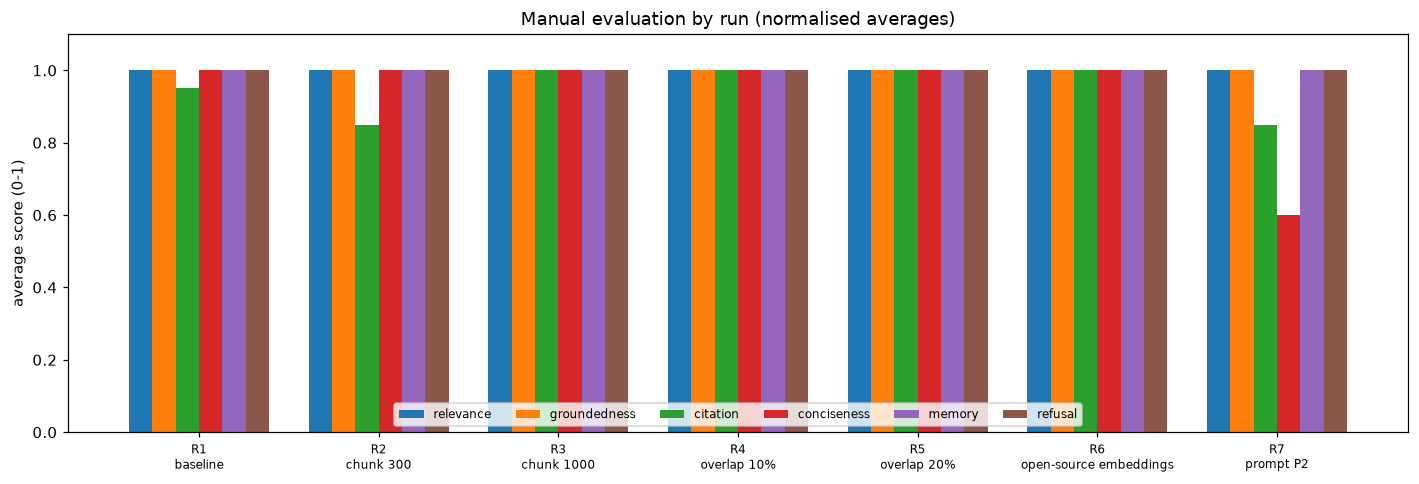

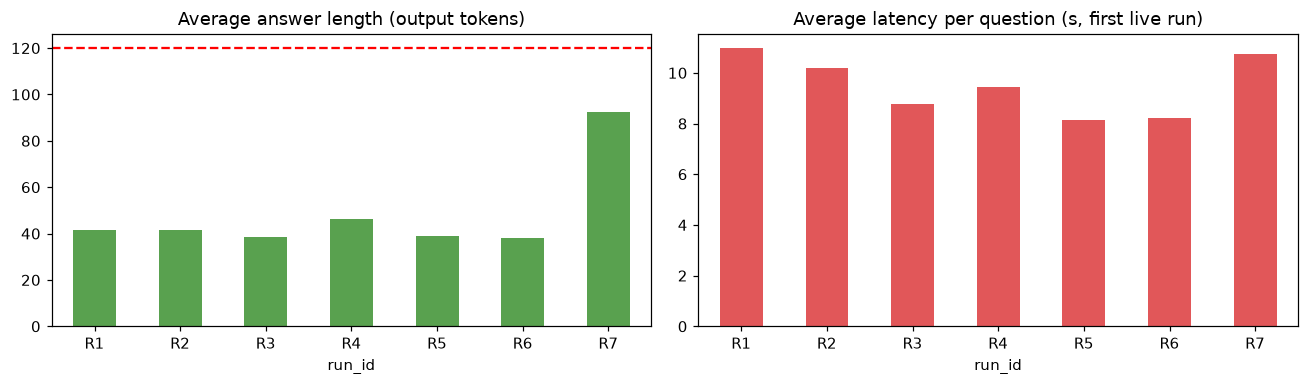

In [17]:
fig, ax = plt.subplots(figsize=(13, 4.5))
crit = ["relevance", "groundedness", "citation", "conciseness", "memory", "refusal"]
x = np.arange(len(agg)); w = 0.13
for i, c in enumerate(crit):
    ax.bar(x + (i - 2.5) * w, agg[c], w, label=c)
ax.set_xticks(x); ax.set_xticklabels([f"{r}\n{agg.loc[r, 'change']}" for r in agg.index], fontsize=8)
ax.set_ylim(0, 1.1); ax.set_ylabel("average score (0-1)"); ax.legend(ncol=6, fontsize=8, loc="lower center")
ax.set_title("Manual evaluation by run (normalised averages)")
plt.tight_layout(); plt.savefig(OUT / "02_run_scores.png"); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
agg["avg_tokens_out"].plot.bar(ax=ax[0], color="#59a14f"); ax[0].set_title("Average answer length (output tokens)"); ax[0].axhline(120, ls="--", c="r")
agg["avg_latency_s"].plot.bar(ax=ax[1], color="#e15759"); ax[1].set_title("Average latency per question (s, first live run)")
for a in ax: a.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig(OUT / "03_tokens_latency.png"); plt.show()

## 8b. Example answers: wins and failures

In [18]:
def show(label, r):
    print(f"=== {label} ===")
    print(f"[{r.run_id} / {r.qid} / {r.q_type}]  Q: {r.question}")
    print(f"Standalone query: {r.standalone_question}")
    print(f"Retrieved: {r.used_chunks}")
    print(f"A: {r.answer}")
    print(f"Scores: " + ", ".join(f"{c}={r[c]:.0f}" for c in SC if pd.notna(r[c])) + f"   Note: {r.note}\n")

for label, r in summarize.pick_examples(ev, agg):
    show(label, r)

=== Win: follow-up resolved through memory ===
[R3 / Q8 / follow-up]  Q: Once I'm promoted to L5, which class can I fly on an 8-hour flight?
Standalone query: What are the flight class entitlements for an L5 employee on an 8-hour flight?
Retrieved: ['01_leave_policy-p2-c0', '03_travel_expense_policy-p1-c0', '07_learning_development_policy-p2-c0', '06_performance_promotion_policy-p2-c0']
A: For flights longer than 6 hours, employees at level L5 and above may book business class [Travel and Expense Policy#1].
Scores: relevance=2, groundedness=2, citation=2, conciseness=1, memory=2   Note: standalone query: What are the flight class entitlements for an L5 employee on an 8-hour flight?

=== Win: correct refusal on an out-of-corpus question ===
[R3 / Q6 / boundary]  Q: Does the company reimburse my gym membership?
Standalone query: Does the company reimburse my gym membership?
Retrieved: ['07_learning_development_policy-p2-c0', '03_travel_expense_policy-p2-c0', '02_remote_work_policy-p2-c0'

## 8c. Recommendation

In [19]:
bench = pd.read_csv(OUT / "retrieval_benchmark.csv")
cold = pd.read_csv(OUT / "embedding_cost_latency.csv", index_col=0)
rec = summarize.recommendation(agg, bench, cold)
json.dump(rec, open(OUT / "recommendation.json", "w"), indent=2)
display(Markdown(f"**Recommended configuration:** chunking {rec['chunk']} · {rec['embedding']} · {rec['prompt']}\n\n" + rec["markdown"]))

**Recommended configuration:** chunking 600 / 20% · Open-source BGE-small · P1 (concise)

- **Chunking: 600 characters, 20% overlap** (run R5). Among the chunking runs it scored the highest overall (1.00), with retrieval MRR 1.00. Smaller chunks give more precise passages, but a policy rule and its condition can be split across chunks. Larger chunks keep rules together, but they put more unrelated text into the prompt (total tokens per run: R1=8310, R2=6404, R3=10873, R4=8338, R5=8261).

- **Embeddings: Open-source BGE-small.** In the end-to-end runs, OpenAI scored 0.99 and BGE 1.00. Across all 9 chunking configurations, average retrieval was: OpenAI recall@4 1.00 / MRR 0.97, against BGE 1.00 / 1.00. OpenAI costs $0.02 per 1M tokens ($0.000054 for this corpus) and takes about 349 ms per query over the network. BGE is free, runs locally in about 16 ms per query, and keeps policy text inside the company. Since quality is essentially equal, the free and private model wins.

- **Prompt: P1 (concise).** P1 averaged 42 output tokens with overall 0.99, and P2 averaged 92 tokens with overall 0.91 (citation 0.95 vs 0.85). P2's evidence bullets make answers easier to audit, but they did not improve accuracy enough to justify the longer output. P1 stays the default, and P2 is useful when an auditor needs to see the evidence.

## Reproducibility

- **Setup:** `pip install -r requirements.txt`, then put `GOOGLE_API_KEY` and `OPENAI_API_KEY` in a `.env` file next to the notebook.
- **Fixed settings:** temperature 0, `top_k = 4` and seed 42, recorded in the config. Gemini 3 models reason briefly before answering; those hidden tokens are logged as `reasoning_tokens` and excluded from the answer-length check. FAISS uses exact search. The corpus is generated deterministically by `make_corpus.py`.
- **Caching:** every LLM response is cached in `cache/llm_cache.sqlite` and every embedding in `cache/embeddings/`. Re-running the notebook therefore makes no new API calls and gives the same answers. Delete `cache/` and set `RERUN = True` to call the APIs again. Even at temperature 0, hosted models can change slightly over time.